In [51]:
import numpy as np
import pandas as pd
import glob
import os
import shutil
import matplotlib.pyplot as plt
import seaborn as sns


In [100]:
# clear folder from redundant files 
DOE = pd.read_csv("./QMC-Initial/qmc/doe_design.csv")
# DOE[DOE.columns[3:]] = DOE[DOE.columns[3:]].apply(lambda x: pd.to_numeric(x, errors='coerce'))
DOE.head()
NEXP = 800

def get_results_by_id(id):
    try:
        loaded_data = pd.read_csv(f"QMC-Initial/qmc/{id}/openlab-sensors-export.csv",)
        loaded_data[loaded_data.columns[3:]] = loaded_data[loaded_data.columns[3:]].apply(lambda x: x.str.replace(',', '.'))
        loaded_data[loaded_data.columns[3:]] = loaded_data[loaded_data.columns[3:]].apply(lambda x: pd.to_numeric(x, errors='coerce'))
        crossings = loaded_data[loaded_data["LC "] >= 300] 
        crossings = crossings[crossings["LC "] <= 400] 
        return crossings
    except FileNotFoundError:
        print(f"FILE for {id} NOT FOUND")
        

def get_np_data(df: pd.DataFrame):
    unique_sensors = df["NODE "].unique()
    rows = {}
    for s in unique_sensors:
        npar = df[df["NODE "] == s][df.columns[-2]].to_numpy()
        npar = np.concat([npar, np.flip(npar,0)])
        # npar = np.pad(npar, 1)
        rows[s]=npar
    return rows

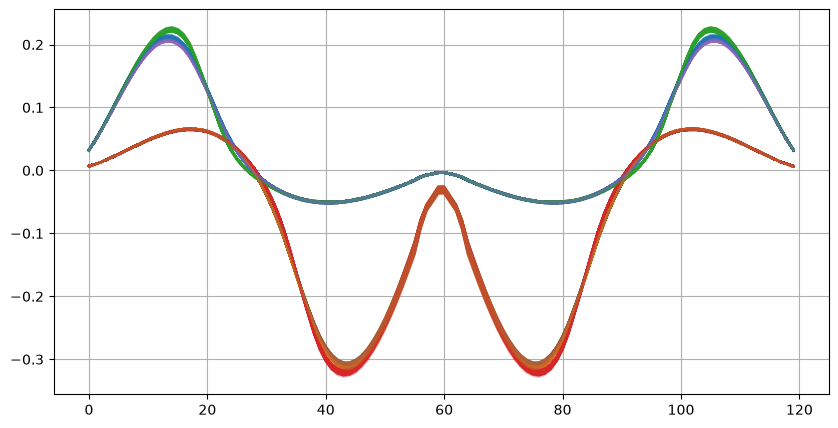

In [ ]:
# crossings[crossings["NODE "] == 1140].plot(y=crossings.columns[-2])

# get np 

colormap = sns.color_palette("tab10", n_colors=6)
plt.figure(figsize=(10,5))
for id in range(NEXP//4):
    crossings = get_results_by_id(id)      
    crossings = get_np_data(crossings)
    for i, (key, value) in enumerate(crossings.items()):    
        plt.plot(value, color = colormap[i], alpha = 0.05 )
    # plt.plot(crossings[1140])
plt.grid()

In [7]:
resultfiles = glob.glob("QMC-Initial/qmc/*/*.csv")
len(resultfiles)
print(resultfiles[0:7])
print(resultfiles[-1])
 

['QMC-Initial/qmc/0/openlab-sensors-export.csv', 'QMC-Initial/qmc/1/openlab-sensors-export.csv', 'QMC-Initial/qmc/10/openlab-sensors-export.csv', 'QMC-Initial/qmc/100/openlab-sensors-export.csv', 'QMC-Initial/qmc/101/openlab-sensors-export.csv', 'QMC-Initial/qmc/102/openlab-sensors-export.csv', 'QMC-Initial/qmc/103/openlab-sensors-export.csv']
QMC-Initial/qmc/999/openlab-sensors-export.csv


In [15]:
counter = 0
nums = []

for rf in resultfiles:
    nums.append(int(rf.split("/")[2]))
nums.sort()
# for n in nums:
#     if not n == counter:
#         print("num missing: ", n)
#     counter += 1


3